**Fetal Head Ultrasound: U-Net with a Pretrained ResNet-34 Encoder**

Notebook 02 trained a plain U-Net from random weights. This notebook trains a second U-Net whose encoder (the half that shrinks the image) is a ResNet-34 that was already trained on ImageNet, and compares the two on the same test images.

Everything except the model is kept the same as notebook 02, so a difference in the scores comes from the model:

| | Notebook 02 (baseline) | This notebook |
|---|---|---|
| Model | Plain U-Net, random start, 7.8M weights | U-Net with ImageNet ResNet-34 encoder, 24.4M weights |
| Data | *src/dataset.py*, *splits.csv*, 256 x 256 | same |
| Augmentation | flip, rotate 15 degrees, brightness/contrast | same |
| Loss | BCE + soft Dice | same |
| Epochs | up to 40, at least 15, stop after 8 without gain | same |
| Learning rate | 1e-3 | 1e-3 for the decoder, 1e-4 for the pretrained encoder |
| Epoch and threshold | picked on validation | same |
| Test scoring | once, Dice, IoU, HC in mm | same |

The learning rate is the one deliberate difference, and the training section explains why.

Run notebook 01 first, and notebook 02 if you want the comparison table at the end. On Colab, pick a GPU runtime (Runtime > Change runtime type > T4 GPU).

In [1]:
!pip install -q segmentation-models-pytorch==0.5.0 "albumentations>=1.4"

In [2]:
import os
import shutil
import subprocess
import sys
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import segmentation_models_pytorch as smp
import torch
from torch import nn

plt.rcParams["figure.dpi"] = 70  # keeps the saved notebook small

**Setup**

All settings are in this one cell. The folders match notebooks 01 and 02: on Colab the data sits in the shared Drive folder *aai-521-hc18*. The repo is cloned so the loader can be imported instead of copied.

The settings that matter most:

- TRAIN: set to True to train the model. Set to False on later runs to skip training and load the saved model and training history from Drive instead. Every cell after training still runs either way.
- ENCODER_LR and DECODER_LR: the two learning rates, explained in the training section.
- MODEL_NAME = "unet_resnet34": every saved file starts with this name, so nothing from notebook 02 (unet_plain) is overwritten.
- BASELINE_NAME = "unet_plain": the notebook 02 results that the last cell compares against.

The image size, batch size, epochs, early stopping and thresholds are copied from notebook 02 and should stay equal to it, or the comparison is no longer fair.

In [3]:
TRAIN = True             # False = skip training, load the saved model from Drive
SEED = 42
IMAGE_SIZE = 256
BATCH_SIZE = 8
ENCODER = "resnet34"
ENCODER_WEIGHTS = "imagenet"  # weights learned on ImageNet photos
ENCODER_LR = 1e-4        # pretrained half: small steps so it is not wiped out
DECODER_LR = 1e-3        # new half: same rate as the notebook 02 baseline
MAX_EPOCHS = 40
MIN_EPOCHS = 15          # always train at least this long before stopping early
PATIENCE = 8             # then stop after this many epochs without a better val Dice
THRESHOLDS = [0.3, 0.4, 0.5, 0.6, 0.7]
MODEL_NAME = "unet_resnet34"
BASELINE_NAME = "unet_plain"   # notebook 02, for the comparison at the end

REPO_URL = (
    "https://github.com/aladenisun/"
    "aai-521-ultrasound-fetal-head-circumference.git"
)

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    DATA_DIR = Path("/content/drive/MyDrive/aai-521-hc18")
    REPO_DIR = Path("/content/aai-521-ultrasound-fetal-head-circumference")
    if REPO_DIR.exists():
        subprocess.run(["git", "-C", str(REPO_DIR), "pull"], check=True)
    else:
        subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)
else:
    cwd = Path.cwd()
    REPO_DIR = cwd.parent if cwd.name == "notebooks" else cwd
    DATA_DIR = Path(os.environ.get("HC18_DATA_DIR", REPO_DIR / "data"))

MODEL_DIR = DATA_DIR / "models"
RESULT_DIR = DATA_DIR / "results"
FIGURE_DIR = DATA_DIR / "figures"
for folder in (MODEL_DIR, RESULT_DIR, FIGURE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(REPO_DIR / "src"))
from dataset import get_dataloaders  # noqa: E402

CHECKPOINT = MODEL_DIR / f"{MODEL_NAME}.pt"
HISTORY_CSV = RESULT_DIR / f"{MODEL_NAME}_history.csv"
if not TRAIN:
    assert CHECKPOINT.exists() and HISTORY_CSV.exists(), (
        "No saved model in Drive yet, run once with TRAIN = True")

torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Data folder: {DATA_DIR}")
print(f"Device: {device}")

Mounted at /content/drive
Data folder: /content/drive/MyDrive/aai-521-hc18
Device: cuda


**Copying the images to the Colab disk**

Reading images from Google Drive is slow the first time, because Drive fetches each file over the network, which can make the first epoch take several minutes. This cell copies the images and masks listed in *splits.csv* to the Colab machine's own disk (*/content/hc18_local*) once per session, using 16 copies at a time, and from then on everything is read from there. Outputs (model, tables, figures, predicted masks) are still saved to Drive so they last after the session ends.

The copy is skipped outside Colab, and files already copied in this session are not copied again.

In [4]:
def copy_one(source, target):
    if not target.exists():
        shutil.copyfile(source, target)


if IN_COLAB:
    LOCAL_DIR = Path("/content/hc18_local")
    names = pd.read_csv(DATA_DIR / "splits.csv")["filename"]
    jobs = []
    for sub in (Path("raw") / "training_set", Path("masks")):
        (LOCAL_DIR / sub).mkdir(parents=True, exist_ok=True)
        jobs += [(DATA_DIR / sub / n, LOCAL_DIR / sub / n) for n in names]
    shutil.copyfile(DATA_DIR / "splits.csv", LOCAL_DIR / "splits.csv")

    start = time.time()
    with ThreadPoolExecutor(max_workers=16) as pool:
        list(pool.map(lambda job: copy_one(*job), jobs))
    print(f"{len(jobs)} files ready on the Colab disk "
          f"({time.time() - start:.0f}s)")
    READ_DIR = LOCAL_DIR
else:
    READ_DIR = DATA_DIR

IMAGE_DIR = READ_DIR / "raw" / "training_set"
MASK_DIR = READ_DIR / "masks"
print(f"Reading images from {READ_DIR}")

1998 files ready on the Colab disk (43s)
Reading images from /content/hc18_local


**Checking the data before training**

The split file from notebook 01 decides which images go where, so it is read here and never re-split. The check makes sure every image in the split file has its mask, and that the loader gives 0/1 masks of the expected shape.

One change from notebook 02: the loader is called with in_channels=3. The ultrasound images are grayscale (one channel), but ResNet-34 was trained on colour photos with three channels (red, green, blue). With in_channels=3 the loader copies the gray image into all three channels, so the encoder sees a gray "color" photo. The masks are unchanged.

In [5]:
splits = pd.read_csv(READ_DIR / "splits.csv")
missing = [name for name in splits["filename"] if not (MASK_DIR / name).exists()]
assert not missing, f"{len(missing)} masks missing, run notebook 01 first"
print(splits["split"].value_counts().to_string())

loaders = get_dataloaders(READ_DIR, image_size=IMAGE_SIZE,
                          batch_size=BATCH_SIZE, augment=True,
                          in_channels=3)
images, masks = next(iter(loaders["train"]))
assert images.shape == (len(images), 3, IMAGE_SIZE, IMAGE_SIZE)
assert masks.shape == (len(images), 1, IMAGE_SIZE, IMAGE_SIZE)
# The three channels are copies of the same gray image.
assert torch.equal(images[:, 0], images[:, 1])
assert torch.equal(images[:, 0], images[:, 2])
assert set(masks.unique().tolist()) <= {0.0, 1.0}
print(f"Batch: images {tuple(images.shape)}, masks {tuple(masks.shape)}, "
      f"mask values {masks.unique().tolist()}")
print(f"Head pixels in this batch: {masks.mean().item():.1%}")

split
train    700
val      150
test     149
Batch: images (8, 3, 256, 256), masks (8, 1, 256, 256), mask values [0.0, 1.0]
Head pixels in this batch: 34.7%


**The model: a U-Net with a pretrained encoder**

The shape is the same U-Net idea as notebook 02: an encoder that shrinks the image, a decoder that grows it back, and skip connections between them. The difference is where the encoder comes from.

- **Encoder**: ResNet-34 with the weights it learned on ImageNet, 1.2 million labelled photos. Its early layers already respond to edges, curves and textures, which is what a skull outline is made of, so the model does not have to learn those from 700 ultrasound images alone. It is 21.3M of the 24.4M weights.
- **Decoder and output layer**: new, random weights, trained from scratch here.

The model comes from the *segmentation_models_pytorch* library (smp.Unet), which builds the decoder and wires up the skip connections. Writing it by hand would add a lot of code without changing the model.

**Handling the grayscale input.** Two steps make a gray ultrasound image look like what the encoder was trained on:

1. The loader repeats the gray channel three times (previous cell).
2. Each channel is shifted and scaled with the ImageNet mean and standard deviation, (x - mean) / std, because those are the numbers the encoder saw during its own training. The values are the standard ImageNet ones: mean 0.485, 0.456, 0.406 and std 0.229, 0.224, 0.225.

Step 2 is done inside the model (PretrainedUNet.forward), so the model takes the same 0 to 1 images from the loader as notebook 02, and the training, validation and prediction code below is unchanged.

There is a second common way to do this: build the model with in_channels=1, and *smp* adds the three colour filters of the first layer into one gray filter. That gives the same result as feeding three identical channels, so either choice is fine. Repeating the channels keeps the pretrained first layer exactly as it was trained.

In [6]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


class PretrainedUNet(nn.Module):
    """smp U-Net with a pretrained encoder, plus ImageNet scaling of the input."""

    def __init__(self, encoder_weights=ENCODER_WEIGHTS):
        super().__init__()
        self.unet = smp.Unet(ENCODER, encoder_weights=encoder_weights,
                             in_channels=3, classes=1)
        # Buffers move to the GPU with the model but are not trained.
        self.register_buffer("mean", torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(IMAGENET_STD).view(1, 3, 1, 1))

    def forward(self, x):
        # x: 3 copies of the gray image, values 0 to 1, from the loader.
        x = (x - self.mean) / self.std
        return self.unet(x)              # one logit per pixel


model = PretrainedUNet().to(device)
n_weights = sum(p.numel() for p in model.parameters())
n_encoder = sum(p.numel() for p in model.unet.encoder.parameters())
print(f"Weights: {n_weights / 1e6:.1f} million "
      f"({n_encoder / 1e6:.1f} million in the pretrained encoder)")

# Shape check: the output must be one channel at the input size.
with torch.no_grad():
    test_out = model(torch.zeros(2, 3, IMAGE_SIZE, IMAGE_SIZE, device=device))
print(f"Output shape for a batch of 2: {tuple(test_out.shape)}")

Weights: 24.4 million (21.3 million in the pretrained encoder)
Output shape for a batch of 2: (2, 1, 256, 256)


**Loss and scores**

The head covers only a minority of the pixels in an image, so a model that guessed "background" everywhere would already be right on most pixels. Pixel accuracy is therefore a poor score. Two overlap scores are used instead, where *P* is the predicted head and *T* the true head:

- Dice = 2 |P and T| / (|P| + |T|)
- IoU = |P and T| / |P or T|

Both run from 0 (no overlap) to 1 (perfect). Dice is always the higher of the two for the same mask.

The training loss adds two parts. Binary cross-entropy (BCE) checks each pixel on its own. Soft Dice loss is 1 minus a Dice score computed on the probabilities instead of the 0/1 mask, so it can be used for training, and it pushes the model toward getting the overall shape right. Using both is a common choice for medical segmentation.

In [7]:
def loss_fn(logits, masks):
    """BCE plus soft Dice loss, averaged over the batch."""
    bce = nn.functional.binary_cross_entropy_with_logits(logits, masks)
    probs = torch.sigmoid(logits)
    overlap = (probs * masks).sum(dim=(1, 2, 3))
    total = probs.sum(dim=(1, 2, 3)) + masks.sum(dim=(1, 2, 3))
    soft_dice = (2 * overlap + 1) / (total + 1)
    return bce + (1 - soft_dice.mean())


def dice_score(pred, truth):
    """Dice for two 0/1 numpy arrays of the same shape."""
    total = pred.sum() + truth.sum()
    if total == 0:
        return 1.0
    return 2 * (pred * truth).sum() / total


def iou_score(pred, truth):
    """IoU (Jaccard) for two 0/1 numpy arrays of the same shape."""
    union = np.logical_or(pred, truth).sum()
    if union == 0:
        return 1.0
    return np.logical_and(pred, truth).sum() / union

**Training**

The training loop is the one from notebook 02: one pass over the 700 training images per epoch with the loader's augmentation, validation Dice at threshold 0.5 after each epoch, weights saved only when validation Dice beats the best so far, learning rate halved after 5 epochs without gain, and early stopping after PATIENCE epochs without gain (never before MIN_EPOCHS, never after MAX_EPOCHS). The test split is not touched here.

**Two learning rates.** The optimizer gets two groups of weights:

- the pretrained encoder at ENCODER_LR = 1e-4
- the new decoder and output layer at DECODER_LR = 1e-3, the same rate as the baseline

At the start the decoder is random, so its error signal is large. With the baseline's rate of 1e-3 everywhere, that signal would push the encoder far from its ImageNet weights in the first epochs and throw away much of what pretraining gave it. A ten times smaller rate for the encoder lets it adjust to ultrasound gradually. This is the usual way to fine-tune a pretrained network, and it is the one setting that differs from notebook 02. The scheduler halves both rates together.

Writing to Drive inside the training loop can be slow, so the best weights are kept on the Colab disk during training and copied to Drive once at the end.

With TRAIN = False this cell trains nothing. It reads the saved history and finds the best epoch in it.

In [8]:
def validation_dice(model, loader):
    """Mean Dice over a loader, threshold 0.5, at the training size."""
    model.eval()
    scores = []
    with torch.no_grad():
        for images, masks in loader:
            logits = model(images.to(device))
            preds = (torch.sigmoid(logits) > 0.5).float().cpu().numpy()
            for pred, truth in zip(preds, masks.numpy()):
                scores.append(dice_score(pred, truth))
    return float(np.mean(scores))


if TRAIN:
    torch.manual_seed(SEED)
    model = PretrainedUNet().to(device)
    optimizer = torch.optim.Adam([
        {"params": model.unet.encoder.parameters(), "lr": ENCODER_LR},
        {"params": model.unet.decoder.parameters(), "lr": DECODER_LR},
        {"params": model.unet.segmentation_head.parameters(),
         "lr": DECODER_LR},
    ])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=5)
    # Fast local copy while training, Drive copy at the end.
    local_dir = Path("/content") if IN_COLAB else MODEL_DIR
    local_checkpoint = local_dir / f"{MODEL_NAME}_training.pt"

    history = []
    best_dice, best_epoch, epochs_without_gain = -1.0, 0, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        start = time.time()
        model.train()
        batch_losses = []
        for images, masks in loaders["train"]:
            images, masks = images.to(device), masks.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(images), masks)
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())

        train_loss = float(np.mean(batch_losses))
        val_dice = validation_dice(model, loaders["val"])
        scheduler.step(val_dice)
        history.append({"epoch": epoch, "train_loss": train_loss,
                        "val_dice": val_dice,
                        "encoder_lr": optimizer.param_groups[0]["lr"],
                        "decoder_lr": optimizer.param_groups[1]["lr"]})

        if val_dice > best_dice:
            best_dice, best_epoch, epochs_without_gain = val_dice, epoch, 0
            torch.save(model.state_dict(), local_checkpoint)
            note = "  saved"
        else:
            epochs_without_gain += 1
            note = ""
        print(f"epoch {epoch:2d}  loss {train_loss:.4f}  val Dice {val_dice:.4f}"
              f"  ({time.time() - start:.0f}s){note}")
        if epoch >= MIN_EPOCHS and epochs_without_gain >= PATIENCE:
            print(f"No gain for {PATIENCE} epochs, stopping.")
            break

    history = pd.DataFrame(history)
    # Copy the best weights and the history to Drive once, at the end.
    shutil.copyfile(local_checkpoint, CHECKPOINT)
    history.to_csv(HISTORY_CSV, index=False)
    print(f"Saved {CHECKPOINT}")
else:
    history = pd.read_csv(HISTORY_CSV)
    best_row = history.loc[history["val_dice"].idxmax()]
    best_epoch, best_dice = int(best_row["epoch"]), float(best_row["val_dice"])
    print("TRAIN is False, loaded the history of the last training run.")

print(f"Best epoch: {best_epoch}, val Dice {best_dice:.4f}")

epoch  1  loss 0.3679  val Dice 0.9626  (13s)  saved
epoch  2  loss 0.1200  val Dice 0.9683  (13s)  saved
epoch  3  loss 0.0893  val Dice 0.9722  (13s)  saved
epoch  4  loss 0.0850  val Dice 0.9728  (13s)  saved
epoch  5  loss 0.0851  val Dice 0.9710  (13s)
epoch  6  loss 0.0718  val Dice 0.9727  (13s)
epoch  7  loss 0.0701  val Dice 0.9736  (13s)  saved
epoch  8  loss 0.0661  val Dice 0.9755  (13s)  saved
epoch  9  loss 0.0611  val Dice 0.9715  (15s)
epoch 10  loss 0.0596  val Dice 0.9739  (15s)
epoch 11  loss 0.0637  val Dice 0.9747  (13s)
epoch 12  loss 0.0626  val Dice 0.9768  (13s)  saved
epoch 13  loss 0.0592  val Dice 0.9762  (14s)
epoch 14  loss 0.0562  val Dice 0.9756  (14s)
epoch 15  loss 0.0549  val Dice 0.9758  (14s)
epoch 16  loss 0.0512  val Dice 0.9773  (14s)  saved
epoch 17  loss 0.0493  val Dice 0.9762  (13s)
epoch 18  loss 0.0504  val Dice 0.9741  (13s)
epoch 19  loss 0.0502  val Dice 0.9757  (13s)
epoch 20  loss 0.0543  val Dice 0.9745  (13s)
epoch 21  loss 0.0618  v

**Training curves**

The loss should fall and the validation Dice should rise and then level off. If the loss keeps falling while validation Dice drops, the model is starting to memorise the training images (overfitting), and the saved best epoch is the one from before that started. The dashed line marks that epoch.

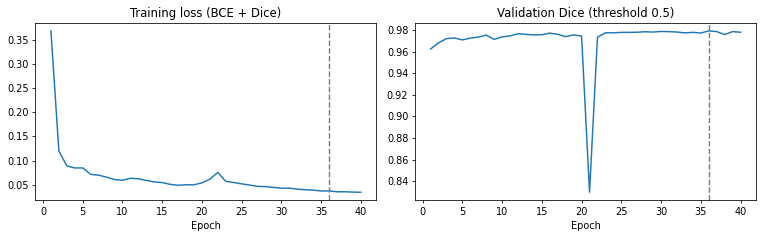

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(history["epoch"], history["train_loss"])
axes[0].set_title("Training loss (BCE + Dice)")
axes[1].plot(history["epoch"], history["val_dice"])
axes[1].set_title("Validation Dice (threshold 0.5)")
for ax in axes:
    ax.axvline(best_epoch, color="gray", linestyle="--")
    ax.set_xlabel("Epoch")
fig.tight_layout()
fig.savefig(FIGURE_DIR / f"{MODEL_NAME}_training_curves.png", dpi=150)
plt.show()

**Predicting at the original image size**

The best epoch's weights are loaded back. For each validation and test image the model gives a 256 x 256 probability map, which is resized back to the image's original size (about 800 x 540). This matters because the square resize stretches the head, and a circumference measured on the stretched mask would be wrong. The loader's return_meta=True option supplies the original size, the pixel size and the doctors' head circumference for each image.

From here on, Dice and IoU are computed at the original size against the saved masks from notebook 01, so they describe the masks that are actually measured.

In [10]:
# encoder_weights=None: no need to download ImageNet weights again,
# every weight is about to be replaced by the saved ones.
model = PretrainedUNet(encoder_weights=None).to(device)
model.load_state_dict(torch.load(CHECKPOINT, map_location=device))
model.eval()

meta_loaders = get_dataloaders(READ_DIR, image_size=IMAGE_SIZE,
                               batch_size=BATCH_SIZE, augment=False,
                               in_channels=3, return_meta=True)
predictions = []   # one dict per image
with torch.no_grad():
    for split in ("val", "test"):
        for images, _, meta in meta_loaders[split]:
            probs = torch.sigmoid(model(images.to(device)))[:, 0].cpu().numpy()
            for i, prob in enumerate(probs):
                width = int(meta["original_width"][i])
                height = int(meta["original_height"][i])
                predictions.append({
                    "split": split,
                    "filename": meta["filename"][i],
                    "pixel_size_mm": float(meta["pixel_size_mm"][i]),
                    "true_hc_mm": float(meta["true_hc_mm"][i]),
                    # cv2.resize takes (width, height)
                    "prob": cv2.resize(prob, (width, height),
                                       interpolation=cv2.INTER_LINEAR),
                })
print(f"Predicted {len(predictions)} images "
      f"({sum(p['split'] == 'test' for p in predictions)} test)")

Predicted 299 images (149 test)


**From mask to millimetres**

This follows the same method notebook 01 used to check the masks, so the numbers are comparable:

1. Take the outer edge of the largest blob in the mask. Small stray blobs are ignored.
2. Drop edge points that lie on the image border, since a head cut off by the frame has a straight edge there that is not skull.
3. Fit an ellipse to the remaining points with OpenCV.
4. Turn the ellipse axes into a circumference with Ramanujan's approximation.
5. Multiply by the image's pixel size to get mm.

If a mask is empty or too small to fit an ellipse, the circumference is recorded as missing and counted below as a failed fit.

Notebook 01 found that the true filled masks read on average about 0.7 mm larger than the doctors' value, because the filled mask includes the width of the drawn line. A model trained on those masks should show a similar small positive bias.

In [11]:
def ellipse_circumference(semi_major, semi_minor):
    """Ramanujan's approximation of the circumference of an ellipse."""
    h = ((semi_major - semi_minor) / (semi_major + semi_minor)) ** 2
    return np.pi * (semi_major + semi_minor) * (
        1 + 3 * h / (10 + np.sqrt(4 - 3 * h)))


def mask_hc_mm(mask, pixel_size_mm):
    """Head circumference in mm from a 0/1 mask at the original size."""
    contours, _ = cv2.findContours(
        mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if not contours:
        return np.nan
    points = max(contours, key=cv2.contourArea).reshape(-1, 2)
    height, width = mask.shape
    inside = ((points[:, 0] > 0) & (points[:, 0] < width - 1)
              & (points[:, 1] > 0) & (points[:, 1] < height - 1))
    points = points[inside]
    if len(points) < 5:          # fitEllipse needs at least 5 points
        return np.nan
    _, axes, _ = cv2.fitEllipse(points)
    return ellipse_circumference(axes[0] / 2, axes[1] / 2) * pixel_size_mm


def score_images(predictions, threshold, split):
    """Dice, IoU and HC error for every image in one split."""
    rows = []
    for p in predictions:
        if p["split"] != split:
            continue
        pred = (p["prob"] >= threshold).astype(np.uint8)
        truth = (cv2.imread(str(MASK_DIR / p["filename"]),
                            cv2.IMREAD_GRAYSCALE) > 127).astype(np.uint8)
        pred_hc = mask_hc_mm(pred, p["pixel_size_mm"])
        rows.append({
            "filename": p["filename"],
            "dice": dice_score(pred, truth),
            "iou": iou_score(pred, truth),
            "true_hc_mm": p["true_hc_mm"],
            "pred_hc_mm": pred_hc,
            "hc_error_mm": pred_hc - p["true_hc_mm"],
        })
    return pd.DataFrame(rows)

**Choosing the threshold on validation**

A pixel counts as head when its probability is at or above the threshold. The usual default is 0.5, but a slightly lower or higher cut-off can fit the skull edge better. Each threshold in THRESHOLDS is tried on the validation split only, and the one with the highest mean validation Dice is kept. The validation HC error is shown too, for information.

In [12]:
sweep = []
for threshold in THRESHOLDS:
    val = score_images(predictions, threshold, "val")
    sweep.append({
        "threshold": threshold,
        "val_dice": val["dice"].mean(),
        "val_iou": val["iou"].mean(),
        "val_hc_mae_mm": val["hc_error_mm"].abs().mean(),
    })
sweep = pd.DataFrame(sweep)
sweep.to_csv(RESULT_DIR / f"{MODEL_NAME}_threshold_sweep.csv", index=False)

best_threshold = float(sweep.loc[sweep["val_dice"].idxmax(), "threshold"])
print(f"Chosen threshold: {best_threshold}")
sweep.round(4)

Chosen threshold: 0.5


,threshold,val_dice,val_iou,val_hc_mae_mm
0,0.3,0.9784,0.9579,2.2658
1,0.4,0.9787,0.9586,1.9938
2,0.5,0.9788,0.9587,1.8295
3,0.6,0.9785,0.9582,1.7444
4,0.7,0.9779,0.9570,1.7698


**Scoring the test split, once**

Everything is now fixed: the weights from the best validation epoch and the threshold chosen on validation. The test split is scored once with those choices and nothing is changed afterwards, so the test numbers are a fair estimate of how the model does on new images.

The table reports:

- Mean Dice and IoU at the original image size.
- HC mean absolute error (MAE), the average size of the error in mm.
- HC mean signed error, which shows whether the model tends to read high (positive) or low (negative). About +0.7 mm is expected from the filled masks.
- HC MAE by head size group, because notebook 01 showed small heads have fainter skulls and fewer examples.
- Failed fits: test images where no ellipse could be fitted.

In [13]:
test = score_images(predictions, best_threshold, "test")
test["size_group"] = pd.cut(test["true_hc_mm"], bins=[0, 100, 200, 400],
                            labels=["under 100 mm", "100 to 200 mm",
                                    "over 200 mm"])
test.to_csv(RESULT_DIR / f"{MODEL_NAME}_test_per_image.csv", index=False)

summary = pd.Series({
    "best epoch": best_epoch,
    "threshold": best_threshold,
    "test images": len(test),
    "Dice (mean)": test["dice"].mean(),
    "IoU (mean)": test["iou"].mean(),
    "HC MAE (mm)": test["hc_error_mm"].abs().mean(),
    "HC mean signed error (mm)": test["hc_error_mm"].mean(),
    "HC median abs error (mm)": test["hc_error_mm"].abs().median(),
    "failed fits": int(test["pred_hc_mm"].isna().sum()),
})
summary.to_frame("value").to_csv(RESULT_DIR / f"{MODEL_NAME}_test_summary.csv")
print(summary.round(3).to_string())
print()
print(test.groupby("size_group", observed=False).agg(
    images=("filename", "size"),
    dice=("dice", "mean"),
    hc_mae_mm=("hc_error_mm", lambda e: e.abs().mean()),
).round(3).to_string())

best epoch                    36.000
threshold                      0.500
test images                  149.000
Dice (mean)                    0.977
IoU (mean)                     0.956
HC MAE (mm)                    2.049
HC mean signed error (mm)      0.647
HC median abs error (mm)       1.687
failed fits                    0.000

               images   dice  hc_mae_mm
size_group                             
under 100 mm       28  0.964      1.654
100 to 200 mm      89  0.981      1.818
over 200 mm        32  0.979      3.035


**Predicted against true head circumference**

Each point is one test image. Points on the gray diagonal are perfect measurements, and points above it are over-estimates. The right panel shows the error against head size, which makes it easy to see if the error grows with larger heads.

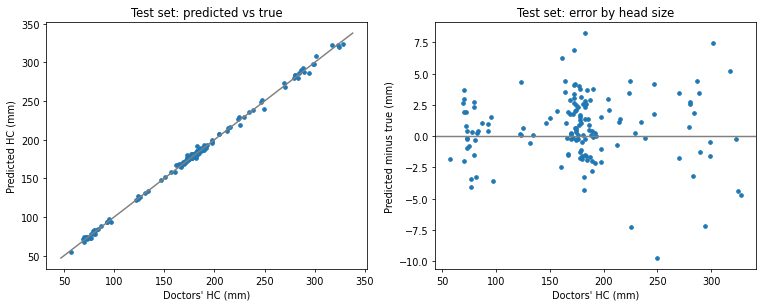

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(test["true_hc_mm"], test["pred_hc_mm"], s=14)
limits = [test["true_hc_mm"].min() - 10, test["true_hc_mm"].max() + 10]
axes[0].plot(limits, limits, color="gray")
axes[0].set_xlabel("Doctors' HC (mm)")
axes[0].set_ylabel("Predicted HC (mm)")
axes[0].set_title("Test set: predicted vs true")
axes[1].scatter(test["true_hc_mm"], test["hc_error_mm"], s=14)
axes[1].axhline(0, color="gray")
axes[1].set_xlabel("Doctors' HC (mm)")
axes[1].set_ylabel("Predicted minus true (mm)")
axes[1].set_title("Test set: error by head size")
fig.tight_layout()
fig.savefig(FIGURE_DIR / f"{MODEL_NAME}_hc_scatter.png", dpi=150)
plt.show()

**Best and worst test images**

Green is the doctors' outline (from the notebook 01 mask) and red is the model. The top row shows the four test images with the highest Dice and the bottom row the four with the lowest. The bottom row shows where the model struggles, for example faint skull edges, heads cut off by the frame, or other bright curves that the model mistakes for skull.

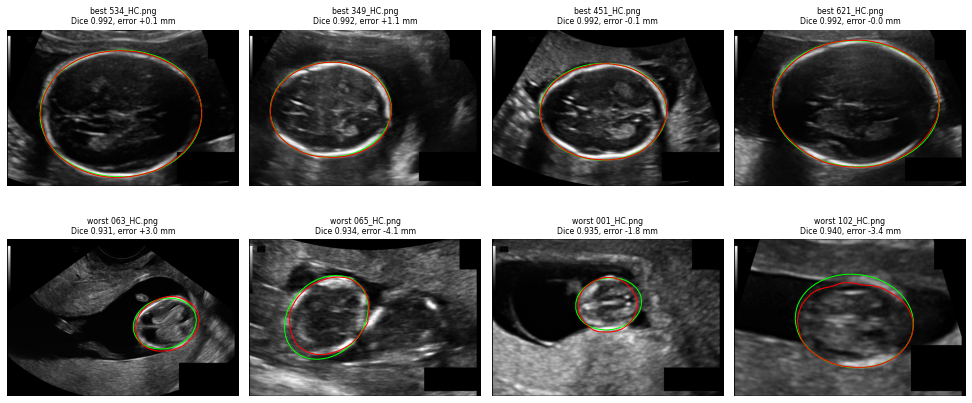

In [15]:
def show_cases(rows, title_prefix, axes_row):
    for ax, row in zip(axes_row, rows.itertuples()):
        image = cv2.imread(str(IMAGE_DIR / row.filename), cv2.IMREAD_GRAYSCALE)
        truth = cv2.imread(str(MASK_DIR / row.filename), cv2.IMREAD_GRAYSCALE)
        prob = next(p["prob"] for p in predictions
                    if p["filename"] == row.filename)
        ax.imshow(image, cmap="gray")
        ax.contour(truth, levels=[127], colors="lime", linewidths=1)
        ax.contour(prob >= best_threshold, levels=[0.5], colors="red",
                   linewidths=1)
        ax.set_title(f"{title_prefix} {row.filename}\nDice {row.dice:.3f}, "
                     f"error {row.hc_error_mm:+.1f} mm", fontsize=8)
        ax.axis("off")


fig, axes = plt.subplots(2, 4, figsize=(14, 6.5))
show_cases(test.nlargest(4, "dice"), "best", axes[0])
show_cases(test.nsmallest(4, "dice"), "worst", axes[1])
fig.tight_layout()
fig.savefig(FIGURE_DIR / f"{MODEL_NAME}_best_worst_test.png", dpi=150)
plt.show()

**Saving the predicted masks**

The predicted masks for validation and test are saved at the original image size as 0/255 PNGs, the same format as the masks from notebook 01, so the measurement notebook can read them the same way. They go to *results/pred_masks/unet_resnet34/* in the shared Drive folder, next to the baseline's folder, so neither overwrites the other.

In [16]:
pred_dir = RESULT_DIR / "pred_masks" / MODEL_NAME
pred_dir.mkdir(parents=True, exist_ok=True)
for p in predictions:
    mask = (p["prob"] >= best_threshold).astype(np.uint8) * 255
    cv2.imwrite(str(pred_dir / p["filename"]), mask)

print(f"Model weights:   {CHECKPOINT}")
print(f"Predicted masks: {pred_dir} ({len(predictions)} files)")
print(f"Tables:          {RESULT_DIR}")
print(f"Figures:         {FIGURE_DIR}")

Model weights:   /content/drive/MyDrive/aai-521-hc18/models/unet_resnet34.pt
Predicted masks: /content/drive/MyDrive/aai-521-hc18/results/pred_masks/unet_resnet34 (299 files)
Tables:          /content/drive/MyDrive/aai-521-hc18/results
Figures:         /content/drive/MyDrive/aai-521-hc18/figures


**Baseline against pretrained**

This cell reads the saved test results of both models from Drive, so it only needs notebook 02 to have been run once with its results saved. It prints three things:

1. The test summary of both models side by side, with the change (pretrained minus baseline). For Dice and IoU higher is better. For the HC errors lower is better, and for the signed error closer to the expected +0.7 mm is better.
2. HC MAE by head size group for both models.
3. A paired check on the head circumference errors. Both models measured the same 149 test images, so each image gives a pair of errors. The cell counts on how many images the pretrained model's error is smaller, and runs a Wilcoxon signed-rank test, which asks whether the paired differences lean one way more than chance would explain. A p-value below 0.05 is the usual cut-off. With 149 images a small difference can easily come out as "not significant", and that is a fair result to report.

The validation curves of both models are plotted together as well. The table is saved as *results/model_comparison.csv* for the report.

                           unet_plain  unet_resnet34  change
best epoch                     40.000         36.000  -4.000
threshold                       0.400          0.500   0.100
test images                   149.000        149.000   0.000
Dice (mean)                     0.974          0.977   0.003
IoU (mean)                      0.951          0.956   0.005
HC MAE (mm)                     2.315          2.049  -0.267
HC mean signed error (mm)       1.215          0.647  -0.568
HC median abs error (mm)        1.589          1.687   0.098
failed fits                     0.000          0.000   0.000

HC MAE (mm) by head size
               unet_plain  unet_resnet34
size_group                              
under 100 mm        1.996          1.654
100 to 200 mm       1.964          1.818
over 200 mm         3.572          3.035

Paired test images: 149
Pretrained error smaller on 86 images, larger on 63
Mean change in abs HC error: -0.267 mm
Wilcoxon signed-rank p-value: 0.0794


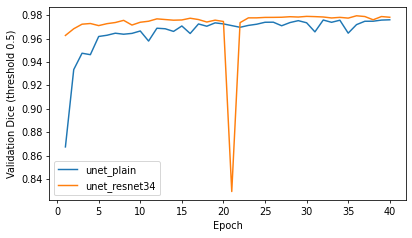

In [17]:
from scipy.stats import wilcoxon

names = [BASELINE_NAME, MODEL_NAME]
baseline_file = RESULT_DIR / f"{BASELINE_NAME}_test_summary.csv"
assert baseline_file.exists(), "Run notebook 02 first to save the baseline results"

# 1. Test summaries side by side
compare = pd.concat(
    [pd.read_csv(RESULT_DIR / f"{name}_test_summary.csv", index_col=0)["value"]
     .rename(name) for name in names], axis=1)
compare["change"] = compare[MODEL_NAME] - compare[BASELINE_NAME]
compare.to_csv(RESULT_DIR / "model_comparison.csv")
print(compare.round(3).to_string())

# 2. HC MAE by head size group
per_image = {name: pd.read_csv(RESULT_DIR / f"{name}_test_per_image.csv")
             for name in names}
by_size = pd.DataFrame({
    name: frame.groupby("size_group")["hc_error_mm"]
               .apply(lambda e: e.abs().mean())
    for name, frame in per_image.items()})
by_size = by_size.reindex(["under 100 mm", "100 to 200 mm", "over 200 mm"])
print()
print("HC MAE (mm) by head size")
print(by_size.round(3).to_string())

# 3. Paired check on the same test images
pairs = per_image[BASELINE_NAME].merge(
    per_image[MODEL_NAME], on="filename", suffixes=("_base", "_pre"))
pairs = pairs.dropna(subset=["hc_error_mm_base", "hc_error_mm_pre"])
abs_base = pairs["hc_error_mm_base"].abs()
abs_pre = pairs["hc_error_mm_pre"].abs()
print()
print(f"Paired test images: {len(pairs)}")
print(f"Pretrained error smaller on {(abs_pre < abs_base).sum()} images, "
      f"larger on {(abs_pre > abs_base).sum()}")
print(f"Mean change in abs HC error: {(abs_pre - abs_base).mean():+.3f} mm")
print(f"Wilcoxon signed-rank p-value: {wilcoxon(abs_pre, abs_base).pvalue:.4f}")

# Validation Dice per epoch for both models
fig, ax = plt.subplots(figsize=(6, 3.5))
for name in names:
    h = pd.read_csv(RESULT_DIR / f"{name}_history.csv")
    ax.plot(h["epoch"], h["val_dice"], label=name)
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation Dice (threshold 0.5)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "baseline_vs_pretrained_val_dice.png", dpi=150)
plt.show()